# Modificando la red neuronal

Ya vimos que aun cambiando la función de interés no convergío como esperariamos. Entonces tocará modificar la red neuronal. Para esta prueba usaremos los mismos datos de entrenamiento.

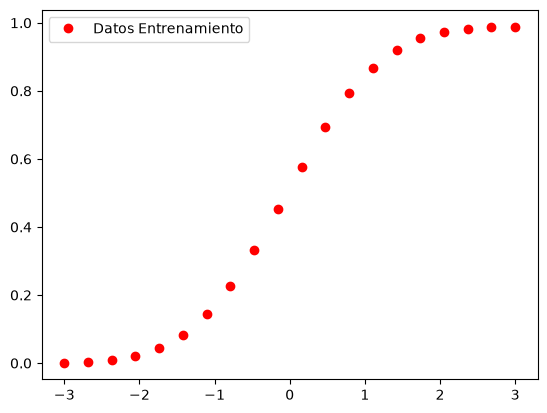

In [6]:
from neuralnetworks.nn import descent_gradent, sigmoid
from neuralnetworks.case_normal import fdist
import numpy as np
import matplotlib.pyplot as plt

train_x = np.linspace(-3,3, 20)
train_y = np.array([fdist(x) for x in train_x])

plt.plot(train_x, train_y, "ro", label="Datos Entrenamiento")
plt.legend()

## Más tiempo.

La exactitud de la red neuronal depende del tiempo de ajuste permitido. Esta se mide en epochs y puede definirse de forma explicita o bajando la cota de error.

0 0.005088473783324006
1000 0.0003469628285532059
2000 0.00014779317453535333
Error 0.0016880859109512658

Mejores parametros
c= 1.0488609870517476
w= 1.2172068270240217
b= -0.023964230572400116


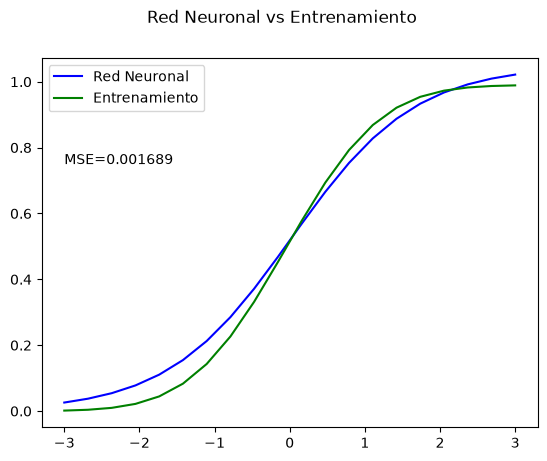

In [12]:
def model(x, theta, func=sigmoid):
    # Se ve sencilla porque es una neurona.
    c = theta[0]
    w = theta[1]
    b = theta[2]
    v = w * x + b
    y = c * func(v)
    return y


def mse_nn(y, x, func, pars):
    pred = [func(t, pars) for t in x]
    diff = (y - pred) ** 2
    error = diff.mean()
    return error


def error_learn(theta):
    value = mse_nn(y = train_y, x = train_x, func=model, pars=theta)
    return value



epsilon = 0.0001
theta_0= [0.1,0.1,0.1]

param_fit = descent_gradent(error_learn, theta_0, epsilon)

print("\nMejores parametros")
print("c=", param_fit[0])
print("w=", param_fit[1])
print("b=", param_fit[2])

def fitmodel(v):
    return model(v, param_fit)

predicted = [fitmodel(x) for x in train_x]
fig, ax = plt.subplots()
ax.plot(train_x, predicted, color="blue", label="Red Neuronal")
ax.plot(train_x, train_y, color="green", label="Entrenamiento")
ax.annotate(text=f"MSE={error_learn(param_fit):2f}", xy=[-3,0.75])
fig.suptitle("Red Neuronal vs Entrenamiento")
ax.legend()